# Validate a structured conversation

**AI & human decisions · 15–25 minutes · learning companion**

A copy-and-paste workflow from Six Hats conversations to editable JSON, SVG maps and human-reviewed synthesis.

**Learning question:** What can a schema check establish about a discussion?

**Source project:** [JupyterLite-Custom-GPT-Six-Thinking-Hats](https://github.com/jltobias/JupyterLite-Custom-GPT-Six-Thinking-Hats).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/empathy-iteration.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Validate that a small authored JSON object contains six nonempty perspectives. The extra purple synthesis step is project-specific, not one of de Bono's original six.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Missing perspectives: []
Empty perspectives: ['green']
Invalid perspectives: {}
Extra metadata keys: []
Authored JSON perspective coverage | valid text entries: {'white': 1, 'red': 1, 'black': 1, 'yellow': 1, 'green': 0, 'blue': 1}


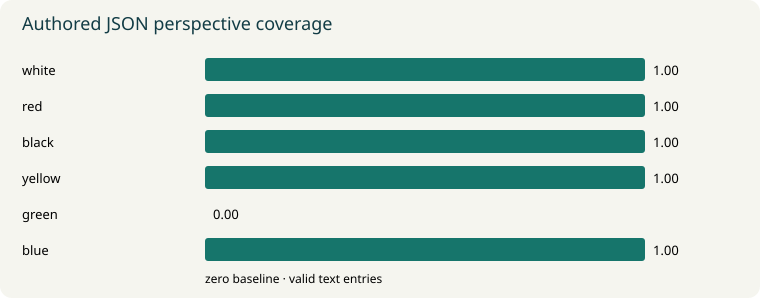

In [2]:
import json
required_hats = ('white', 'red', 'black', 'yellow', 'green', 'blue')

def validate_perspectives(record):
    missing, empty, invalid = [], [], {}
    counts = {hat: 0 for hat in required_hats}
    if not isinstance(record, dict):
        return counts, {'missing': list(required_hats), 'empty': [], 'invalid': {'record': 'Expected a JSON object'}}
    for hat in required_hats:
        if hat not in record:
            missing.append(hat)
            continue
        items = record[hat]
        if not isinstance(items, list):
            invalid[hat] = 'Expected a list of nonempty text entries'
        elif not items:
            empty.append(hat)
        else:
            bad = [i for i, text in enumerate(items) if not isinstance(text, str) or not text.strip()]
            counts[hat] = len(items) - len(bad)
            if bad:
                invalid[hat] = 'Invalid entry indices: ' + str(bad)
    return counts, {'missing': missing, 'empty': empty, 'invalid': invalid}

record = json.loads('{"white": ["Check source dates"], "red": ["Concern about exclusion"], "black": ["Privacy risk"], "yellow": ["Shared learning"], "green": [], "blue": ["Invite review"]}')
counts, issues = validate_perspectives(record)
print('Missing perspectives:', issues['missing'])
print('Empty perspectives:', issues['empty'])
print('Invalid perspectives:', issues['invalid'])
print('Extra metadata keys:', sorted(set(record)-set(required_hats)) if isinstance(record, dict) else [])
bars(counts, 'Authored JSON perspective coverage', 'valid text entries')

## Interpret the result

The green alternatives field is empty. Valid JSON and complete fields still cannot establish factual accuracy, consent or good judgment.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Add an alternative and an evidence URL field. Separate structural validity, source verification and stakeholder approval into three checks.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Custom-GPT-Six-Thinking-Hats](https://github.com/jltobias/JupyterLite-Custom-GPT-Six-Thinking-Hats).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Custom-GPT-Six-Thinking-Hats/blob/5fd19d41de4500575d34a3707666bb771054bf90/README.md); inspected 2026-11-01, commit `5fd19d41de45`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

Source uses deliberate paste and no live calls. Optional ChatGPT plugin access depends on workspace permissions. Do not assume another learner has access; manually authored JSON is supported.

- [Run source Lab](https://jltobias.github.io/JupyterLite-Custom-GPT-Six-Thinking-Hats/lite/lab/index.html) - Run the source project notebooks; its dependencies and data terms apply. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Read source Book](https://jltobias.github.io/JupyterLite-Custom-GPT-Six-Thinking-Hats/book/index.html) - Read the original project course and its own source notes. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Open source learning hub](https://jltobias.github.io/JupyterLite-Custom-GPT-Six-Thinking-Hats/) - Choose among the source project learning experiences. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
